# 03 - KPIs

Los 5 indicadores del proyecto. Cada uno con su grafica para el dashboard.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

tabla = pd.read_csv('../data/datos_limpios.csv')

In [2]:
kpi1 = tabla['global'].mean()
print('KPI 1 - Puntaje global promedio:', round(kpi1, 1))

KPI 1 - Puntaje global promedio: 246.9


In [3]:
kpi2 = tabla['matematicas'].mean()
print('KPI 2 - Promedio matematicas:', round(kpi2, 1))

KPI 2 - Promedio matematicas: 49.7


In [4]:
kpi3 = tabla['lectura'].mean()
print('KPI 3 - Promedio lectura critica:', round(kpi3, 1))

KPI 3 - Promedio lectura critica: 52.2


In [5]:
prom_rural = tabla[tabla['zona'] == 'RURAL']['global'].mean()
prom_urbana = tabla[tabla['zona'] == 'URBANO']['global'].mean()
kpi4 = prom_urbana - prom_rural
print('KPI 4 - Brecha rural-urbana:', round(kpi4, 1), 'puntos')

KPI 4 - Brecha rural-urbana: 28.7 puntos


In [6]:
# Se calcula sobre los que respondieron si o no, los "No informado" no cuentan
respondieron = tabla[tabla['internet'].isin(['Si', 'No'])]
kpi5 = (respondieron['internet'] == 'Si').mean() * 100
print('KPI 5 - Hogares con internet:', round(kpi5, 1), '% de', len(respondieron), 'que respondieron')

KPI 5 - Hogares con internet: 67.3 % de 2558 que respondieron


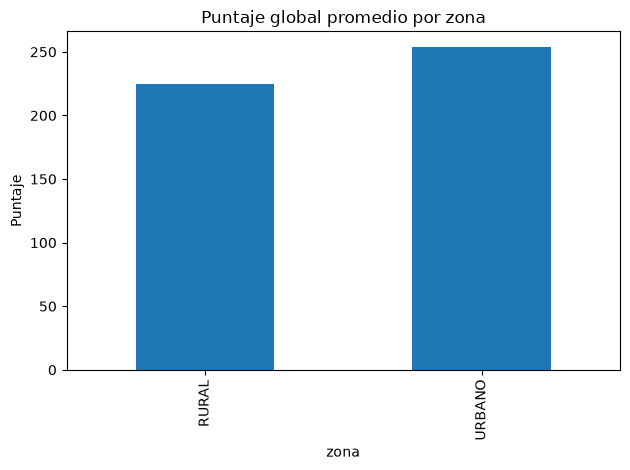

In [7]:
tabla.groupby('zona')['global'].mean().plot(kind='bar')
plt.title('Puntaje global promedio por zona')
plt.ylabel('Puntaje')
plt.tight_layout()
plt.savefig('../docs/img/promedio_por_zona.png')
plt.show()

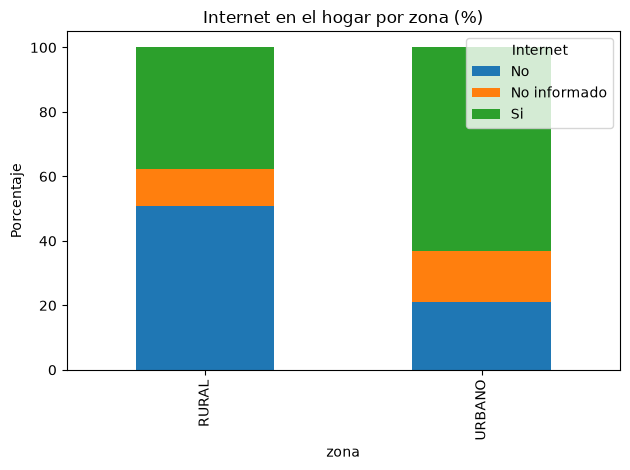

In [8]:
porcentaje = pd.crosstab(tabla['zona'], tabla['internet'], normalize='index') * 100
porcentaje.plot(kind='bar', stacked=True)
plt.title('Internet en el hogar por zona (%)')
plt.ylabel('Porcentaje')
plt.legend(title='Internet')
plt.tight_layout()
plt.savefig('../docs/img/internet_por_zona.png')
plt.show()